# Security Log Investigation — Task 3

**Track:** Cyber Security · **Level:** Beginner-Friendly  
**Objective:** Ingest and normalize synthetic authentication logs, establish an authentication baseline, run deterministic detection rules (Password Spraying, Brute-Force Attack, Unusual Access), reconstruct a chronological incident timeline, and separate confirmed facts from analyst inference and unverified assumptions.

## 1. Dataset Description & Scope
- **Source Dataset:** `../data/authentication-log-sample.csv` (from `https://edvyro.in/datasets/source-materials/authentication-log-sample.csv`)
- **Handling Policy:** The original CSV is read strictly read-only and never modified. All normalized outputs are stored in a separate CSV.
- **IP Range Notice:** All IPv4 addresses belong to RFC 5737 documentation blocks (`192.0.2.0/24`, `198.51.100.0/24`, `203.0.113.0/24`).

## 2. Libraries & Environment Setup

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.log_parser import load_raw_logs, inspect_raw_schema
from src.normalization import normalize_logs
from src.detection_rules import (
    PasswordSprayingConfig,
    BruteForceConfig,
    UnusualAccessConfig,
    detect_password_spraying,
    detect_brute_force,
    detect_unusual_access,
    run_all_detections,
)
from src.timeline import (
    compute_baseline_metrics,
    build_incident_timeline,
    build_evidence_assessment,
    assess_incident_severity,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)
print("Project Root:", PROJECT_ROOT)

Project Root: /app/applet/interntask2/task-3-security-log-investigation


## 3. Data Ingestion & Initial Dataset Inspection

In [2]:
raw_csv_path = PROJECT_ROOT / "data" / "authentication-log-sample.csv"
raw_df = load_raw_logs(raw_csv_path)
schema_info = inspect_raw_schema(raw_df)
print("Schema Summary:", schema_info)
raw_df

Schema Summary: {'columns': ['timestamp', 'user_id', 'source_ip', 'event', 'result', 'device'], 'matches_expected_columns': True, 'total_input_records': 12, 'missing_values_by_field': {'timestamp': 0, 'user_id': 0, 'source_ip': 0, 'event': 0, 'result': 0, 'device': 0}, 'exact_duplicate_count': 0}


,evidence_id,raw_row_number,timestamp,user_id,source_ip,event,result,device
0,EV-01,2,2026-08-01T09:00:12Z,stu-104,192.0.2.18,password_login,success,android
1,EV-02,3,2026-08-01T09:03:44Z,stu-117,198.51.100.27,password_login,failure,windows
2,EV-03,4,2026-08-01T09:04:01Z,stu-117,198.51.100.27,password_login,failure,windows
3,EV-04,5,2026-08-01T09:04:18Z,stu-117,198.51.100.27,password_login,failure,windows
4,EV-05,6,2026-08-01T09:05:03Z,stu-117,198.51.100.27,account_lock,success,server
5,EV-06,7,2026-08-01T09:21:10Z,stu-209,203.0.113.42,password_login,failure,unknown
6,EV-07,8,2026-08-01T09:21:13Z,stu-311,203.0.113.42,password_login,failure,unknown
7,EV-08,9,2026-08-01T09:21:17Z,stu-415,203.0.113.42,password_login,failure,unknown
8,EV-09,10,2026-08-01T09:21:22Z,stu-502,203.0.113.42,password_login,failure,unknown
9,EV-10,11,2026-08-01T09:22:01Z,stu-209,203.0.113.42,rate_limit,blocked,server


## 4. Data-Quality Assessment & Normalization

In [3]:
norm_df, quality_summary = normalize_logs(raw_df)
for key, val in quality_summary.items():
    if key != "transformation_log":
        print(f"{key}: {val}")

print("\nTransformations Applied:")
for step in quality_summary["transformation_log"]:
    print(" -", step)

norm_df[["evidence_id", "timestamp_utc", "source_ip_normalized", "account_normalized", "action_normalized", "event_category", "result_normalized", "device_normalized", "is_duplicate", "is_valid_record", "normalization_notes"]]

total_input_records: 12
valid_records: 12
duplicate_records: 0
missing_values_by_field: {'timestamp': 0, 'user_id': 0, 'source_ip': 0, 'event': 0, 'result': 0, 'device': 0}
invalid_timestamps: 0
invalid_ip_addresses: 0
excluded_records_count: 0
excluded_records: []
unknown_device_records: 4
documentation_ip_records: 12

Transformations Applied:
 - Preserved all original columns with 'raw_' prefix and added stable 'evidence_id' (EV-01..EV-N).
 - Parsed 'timestamp' into timezone-aware UTC timestamps (ISO-8601 'timestamp_utc') via pandas.to_datetime(utc=True).
 - Validated and canonicalized 'source_ip' using Python's ipaddress.ip_address() and flagged RFC 5737 documentation IPs.
 - Normalized 'user_id' into lowercase trimmed 'account_normalized' without altering 'raw_user_id'.
 - Standardized 'event' into 'action_normalized' and classified into 'event_category' (authentication vs security_control vs session_maintenance).
 - Standardized 'result' into 'result_normalized' (success, failure,

,evidence_id,timestamp_utc,source_ip_normalized,account_normalized,action_normalized,event_category,result_normalized,device_normalized,is_duplicate,is_valid_record,normalization_notes
0,EV-01,2026-08-01T09:00:12Z,192.0.2.18,stu-104,password_login,authentication,success,android,False,True,clean
1,EV-02,2026-08-01T09:03:44Z,198.51.100.27,stu-117,password_login,authentication,failure,windows,False,True,clean
2,EV-03,2026-08-01T09:04:01Z,198.51.100.27,stu-117,password_login,authentication,failure,windows,False,True,clean
3,EV-04,2026-08-01T09:04:18Z,198.51.100.27,stu-117,password_login,authentication,failure,windows,False,True,clean
4,EV-05,2026-08-01T09:05:03Z,198.51.100.27,stu-117,account_lock,security_control,success,server,False,True,clean
5,EV-06,2026-08-01T09:21:10Z,203.0.113.42,stu-209,password_login,authentication,failure,unknown,False,True,device_reported_as_unknown
6,EV-07,2026-08-01T09:21:13Z,203.0.113.42,stu-311,password_login,authentication,failure,unknown,False,True,device_reported_as_unknown
7,EV-08,2026-08-01T09:21:17Z,203.0.113.42,stu-415,password_login,authentication,failure,unknown,False,True,device_reported_as_unknown
8,EV-09,2026-08-01T09:21:22Z,203.0.113.42,stu-502,password_login,authentication,failure,unknown,False,True,device_reported_as_unknown
9,EV-10,2026-08-01T09:22:01Z,203.0.113.42,stu-209,rate_limit,security_control,blocked,server,False,True,clean


## 5. Authentication Baseline & Exploratory Data Analysis
Notice how `account_lock` (`EV-05`) has `result='success'` and `device='server'`. By categorizing events into `authentication` vs. `security_control`, we ensure defensive lockout confirmations are never miscounted as successful user logins.

In [4]:
baseline = compute_baseline_metrics(norm_df)
for k, v in baseline.items():
    print(f"{k}: {v}")

total_events: 12
password_login_attempts: 9
successful_logins: 2
failed_logins: 7
security_control_events: 2
session_refresh_events: 1
unique_source_ips: 4
unique_accounts: 6
time_span_start: 2026-08-01T09:00:12Z
time_span_end: 2026-08-01T11:47:09Z
events_by_ip: {'203.0.113.42': 5, '198.51.100.27': 4, '192.0.2.18': 2, '192.0.2.99': 1}
failed_logins_by_account: {'stu-117': 3, 'stu-209': 1, 'stu-311': 1, 'stu-415': 1, 'stu-502': 1}
all_outcomes_distribution: {('account_lock', 'success'): 1, ('password_login', 'failure'): 7, ('password_login', 'success'): 2, ('rate_limit', 'blocked'): 1, ('refresh_token', 'success'): 1}


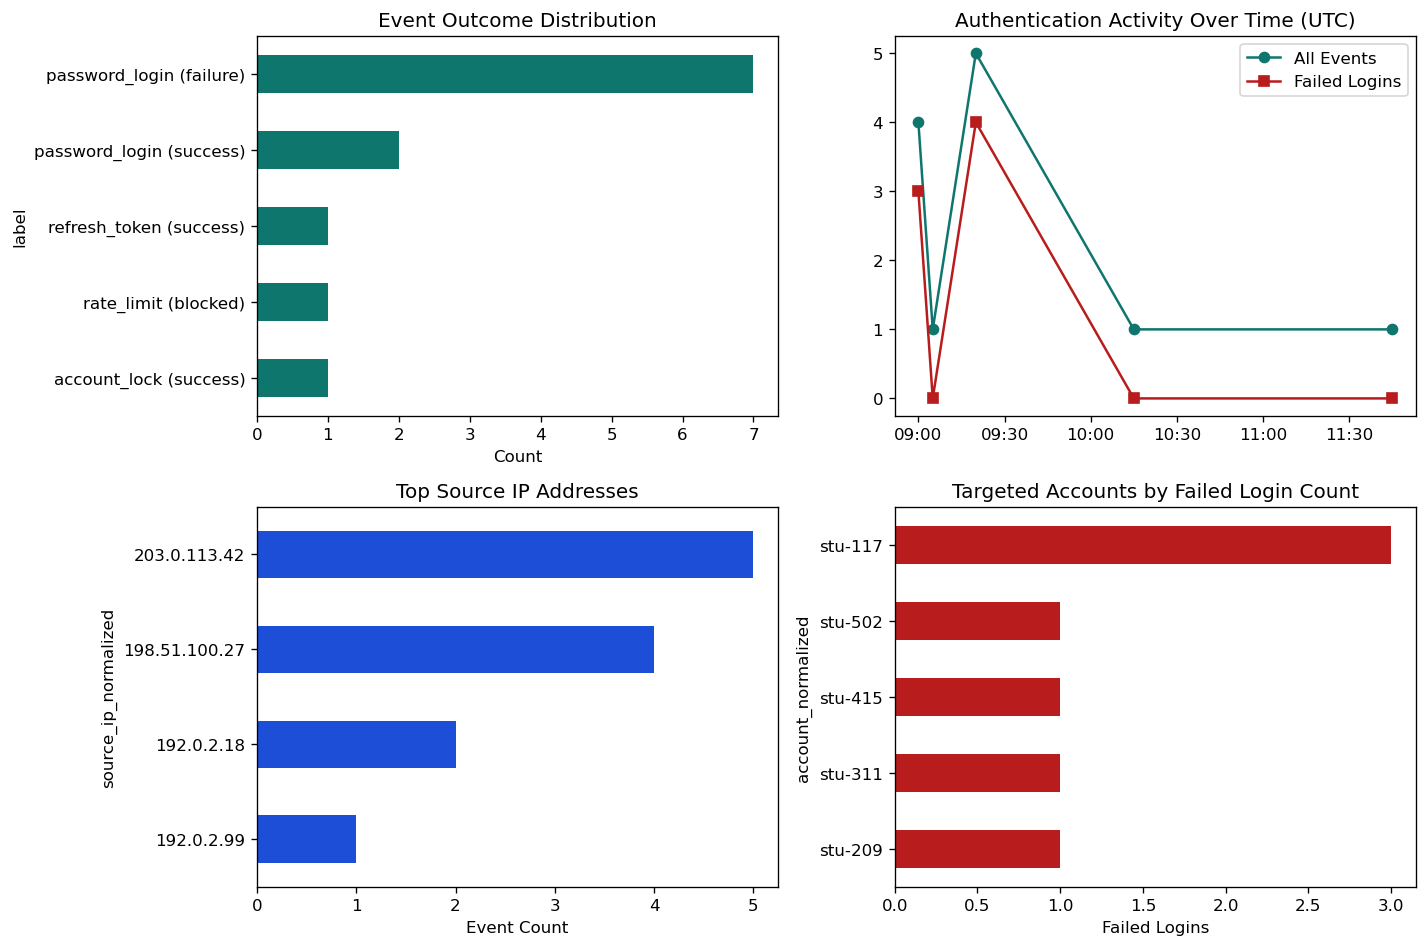

In [5]:
valid = norm_df.loc[norm_df["is_valid_record"]].copy()
valid["timestamp_dt"] = pd.to_datetime(valid["timestamp_utc"], utc=True)

fig, axes = plt.subplots(2, 2, figsize=(12, 8), dpi=120)

# Chart 1: Outcome distribution
outcomes = valid.assign(label=valid["action_normalized"] + " (" + valid["result_normalized"] + ")").groupby("label").size().sort_values()
outcomes.plot(kind="barh", ax=axes[0, 0], color="#0F766E")
axes[0, 0].set_title("Event Outcome Distribution")
axes[0, 0].set_xlabel("Count")

# Chart 2: Events over time
valid["minute_bucket"] = valid["timestamp_dt"].dt.floor("5min")
all_t = valid.groupby("minute_bucket").size()
fail_t = valid.loc[(valid["action_normalized"] == "password_login") & (valid["result_normalized"] == "failure")].groupby("minute_bucket").size().reindex(all_t.index, fill_value=0)
axes[0, 1].plot(all_t.index, all_t.values, marker="o", label="All Events", color="#0F766E")
axes[0, 1].plot(fail_t.index, fail_t.values, marker="s", label="Failed Logins", color="#B91C1C")
axes[0, 1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
axes[0, 1].set_title("Authentication Activity Over Time (UTC)")
axes[0, 1].legend()

# Chart 3: Top Source IPs
valid.groupby("source_ip_normalized").size().sort_values().plot(kind="barh", ax=axes[1, 0], color="#1D4ED8")
axes[1, 0].set_title("Top Source IP Addresses")
axes[1, 0].set_xlabel("Event Count")

# Chart 4: Top Targeted Accounts (Failed password_login)
valid.loc[(valid["action_normalized"] == "password_login") & (valid["result_normalized"] == "failure")].groupby("account_normalized").size().sort_values().plot(kind="barh", ax=axes[1, 1], color="#B91C1C")
axes[1, 1].set_title("Targeted Accounts by Failed Login Count")
axes[1, 1].set_xlabel("Failed Logins")

plt.tight_layout()
plt.show()

## 6. Detection Rules (Password Spraying, Brute-Force, Unusual Access)

In [6]:
spray_cfg = PasswordSprayingConfig(window_minutes=15, min_distinct_accounts=3, min_total_failures=3, max_failures_per_account=2)
brute_cfg = BruteForceConfig(window_minutes=15, min_failures=3)
unusual_cfg = UnusualAccessConfig(prior_failure_lookback_hours=24)

spray_hits = detect_password_spraying(norm_df, spray_cfg)
brute_hits = detect_brute_force(norm_df, brute_cfg)
unusual_hits = detect_unusual_access(norm_df, unusual_cfg)

print(f"Password Spraying detections: {len(spray_hits)}")
print(f"Brute-Force detections: {len(brute_hits)}")
print(f"Unusual Access detections: {len(unusual_hits)}")

detections_df = run_all_detections(norm_df, spray_cfg, brute_cfg, unusual_cfg)
detections_df[["detection_id", "detection_category", "source_ip", "affected_accounts", "failure_count", "success_count", "severity", "confidence", "supporting_event_ids"]]

Password Spraying detections: 1
Brute-Force detections: 1
Unusual Access detections: 1


,detection_id,detection_category,source_ip,affected_accounts,failure_count,success_count,severity,confidence,supporting_event_ids
0,DET-01,Brute-Force Attack,198.51.100.27,stu-117,3,0,Medium,High,"EV-02, EV-03, EV-04, EV-05"
1,DET-02,Password Spraying,203.0.113.42,"stu-209, stu-311, stu-415, stu-502",4,0,High,High,"EV-06, EV-07, EV-08, EV-09, EV-10"
2,DET-03,Unusual Access,192.0.2.99,stu-311,1,1,Medium,Medium,"EV-07, EV-12"


In [7]:
for _, row in detections_df.iterrows():
    print(f"[{row['detection_id']}] {row['detection_category']} ({row['severity']} / Confidence: {row['confidence']})")
    print("  Threshold:", row["threshold"])
    print("  Explanation:", row["explanation"])
    print()

[DET-01] Brute-Force Attack (Medium / Confidence: High)
  Threshold: >= 3 failed password_login attempts per account within 15m
  Explanation: Account stu-117 experienced 3 consecutive failed password_login attempts from 198.51.100.27 within 34 seconds. Defensive account_lock (EV-05) mitigated the burst; no successful login followed.

[DET-02] Password Spraying (High / Confidence: High)
  Threshold: >= 3 distinct accounts, >= 3 failures, <= 2 failures/account within 15m
  Explanation: Source IP 203.0.113.42 recorded 4 failed password_login attempts across 4 distinct accounts (stu-209, stu-311, stu-415, stu-502) within 12 seconds (1–1 attempt(s) per account), matching horizontal password spraying behavior. Defensive rate_limit triggered (EV-10).

[DET-03] Unusual Access (Medium / Confidence: Medium)
  Threshold: Successful password_login within 24h after prior failure or source IP change
  Explanation: Account stu-311 recorded a successful password_login (EV-12) from 192.0.2.99 (ios) af

## 7. Chronological Incident Timeline

In [8]:
timeline_df = build_incident_timeline(norm_df, detections_df)
timeline_df

,timestamp,source_ip,account,action,result,device,associated_detection,evidence_reference,analyst_interpretation
0,2026-08-01T09:00:12Z,192.0.2.18,stu-104,password_login,success,android,None (Baseline Activity),EV-01 (CSV line 2),Confirmed baseline password_login (success) for stu-104 from 192.0.2.18 (android).
1,2026-08-01T09:03:44Z,198.51.100.27,stu-117,password_login,failure,windows,DET-01 (Brute-Force Attack),EV-02 (CSV line 3),Confirmed rapid password_login failure for stu-117 from 198.51.100.27 (windows); part of single-account brute-force ...
2,2026-08-01T09:04:01Z,198.51.100.27,stu-117,password_login,failure,windows,DET-01 (Brute-Force Attack),EV-03 (CSV line 4),Confirmed rapid password_login failure for stu-117 from 198.51.100.27 (windows); part of single-account brute-force ...
3,2026-08-01T09:04:18Z,198.51.100.27,stu-117,password_login,failure,windows,DET-01 (Brute-Force Attack),EV-04 (CSV line 5),Confirmed rapid password_login failure for stu-117 from 198.51.100.27 (windows); part of single-account brute-force ...
4,2026-08-01T09:05:03Z,198.51.100.27,stu-117,account_lock,success,server,DET-01 (Brute-Force Attack),EV-05 (CSV line 6),Confirmed defensive account_lock triggered by server for stu-117 following 3 rapid failures from 198.51.100.27. (Con...
5,2026-08-01T09:21:10Z,203.0.113.42,stu-209,password_login,failure,unknown,DET-02 (Password Spraying),EV-06 (CSV line 7),Confirmed password_login failure for stu-209 from 203.0.113.42 (device=unknown); part of multi-account password spray.
6,2026-08-01T09:21:13Z,203.0.113.42,stu-311,password_login,failure,unknown,DET-02 (Password Spraying); DET-03 (Unusual Access),EV-07 (CSV line 8),Confirmed password_login failure for stu-311 from 203.0.113.42 (device=unknown); part of multi-account password spray.
7,2026-08-01T09:21:17Z,203.0.113.42,stu-415,password_login,failure,unknown,DET-02 (Password Spraying),EV-08 (CSV line 9),Confirmed password_login failure for stu-415 from 203.0.113.42 (device=unknown); part of multi-account password spray.
8,2026-08-01T09:21:22Z,203.0.113.42,stu-502,password_login,failure,unknown,DET-02 (Password Spraying),EV-09 (CSV line 10),Confirmed password_login failure for stu-502 from 203.0.113.42 (device=unknown); part of multi-account password spray.
9,2026-08-01T09:22:01Z,203.0.113.42,stu-209,rate_limit,blocked,server,DET-02 (Password Spraying),EV-10 (CSV line 11),Confirmed defensive rate_limit blocked request for stu-209 from 203.0.113.42 shortly after multi-account spray.


## 8. Evidence vs. Assumptions Assessment

In [9]:
assessment = build_evidence_assessment(norm_df, detections_df)
for category, items in assessment.items():
    print(f"=== {category.upper().replace('_', ' ')} ===")
    for item in items:
        print(f"- {item['finding']} [{item['evidence_reference']} | {item['confidence']}]")
        print(f"  Details: {item['details']}")
        print(f"  Missing: {item['missing_information']}")
    print()

=== CONFIRMED EVIDENCE ===
- DET-01: Brute-Force Burst on stu-117 [EV-02, EV-03, EV-04, EV-05 | High]
  Details: 3 failed password_login attempts against stu-117 from 198.51.100.27 between 2026-08-01T09:03:44Z and 2026-08-01T09:04:18Z, followed by account_lock.
  Missing: HTTP User-Agent, targeted application endpoint, and user confirmation.
- DET-02: Password Spraying from 203.0.113.42 [EV-06, EV-07, EV-08, EV-09, EV-10 | High]
  Details: 4 failed password_login attempts across stu-209, stu-311, stu-415, stu-502 within 12 seconds (2026-08-01T09:21:10Z to 2026-08-01T09:21:22Z), followed by rate_limit block.
  Missing: Whether additional accounts were probed outside this sample window.
- DET-03: Unusual Subsequent Success for stu-311 [EV-07, EV-12 | Medium]
  Details: password_login success at 2026-08-01T11:47:09Z from 192.0.2.99 (ios) following prior failure at 2026-08-01T09:21:13Z from 203.0.113.42.
  Missing: MFA challenge logs, post-login session activity, and user confirmation of i

## 9. Incident Severity Assessment

In [10]:
severity = assess_incident_severity(detections_df)
print("Overall Incident Severity:", severity["overall_severity"])
print("Compromise Confirmed:", severity["compromise_confirmed"])
print("Rationale:", severity["rationale"])

Overall Incident Severity: High
Compromise Confirmed: False
Rationale: Overall incident severity is classified as High. Multiple targeted accounts (4 accounts in rapid password spraying from 203.0.113.42, plus 1 account receiving a 3-attempt brute-force burst from 198.51.100.27) justify High attention. While defensive controls (account_lock and rate_limit) fired, stu-311 recorded a subsequent successful login from a new IP/device (EV-12); because post-login audit logs and user confirmation are absent, compromise remains unconfirmed and requires verification.


## 10. Incident Response Recommendations

- **Phase 1 — Immediate Response:** Verify `EV-12` (`stu-311` login at `11:47:09Z` from `192.0.2.99` / `ios`) out-of-band with the account owner; revoke tokens and reset credentials if unauthorized; preserve raw logs.
- **Phase 2 — Containment:** Tighten per-IP rate limiting against multi-account sprays (`203.0.113.42`), validate `account_lock` recovery controls on `stu-117`, and monitor all five targeted accounts.
- **Phase 3 — Long-Term Improvements:** Enforce MFA, capture User-Agent and post-login audit events, centralize SIEM alerting, and maintain documented response playbooks.

## 11. Final Investigation Summary
All 12 events in `authentication-log-sample.csv` were preserved untouched, normalized deterministically, and analyzed without fabricating findings. Three rule detections (`DET-01` Brute-Force on `stu-117`, `DET-02` Password Spraying from `203.0.113.42`, and `DET-03` Unusual Access on `stu-311`) emerged with clear evidence traceability.